# Phân tích các yếu tố ảnh hưởng đến rating người dùng trên MovieLens bằng cách kết hợp dữ liệu thông tin phim (TMDb)

Dữ liệu tương quan cho thấy nhiều hiện tượng thú vị về hành vi người xem và bản chất ngành điện ảnh. Đầu tiên, mối tương quan âm nhẹ giữa kinh phí sản xuất và điểm đánh giá (-0,19) cho thấy việc đầu tư lớn không đồng nghĩa với chất lượng cao. Các phim bom tấn tập trung vào kỹ xảo và tính giải trí nên dễ bán vé nhưng lại khó chiều lòng cộng đồng yêu phim vốn coi trọng chiều sâu kịch bản, diễn xuất hoặc thông điệp nghệ thuật. Điều này dẫn đến nghịch lý quen thuộc: "Đầu tư lớn có thể tạo ra sự hoành tráng, nhưng không mua được kịch bản hay".

Ngược lại, sự tương quan cực mạnh (+0,81) giữa điểm trung bình của TMDB và MovieLens thể hiện sự đồng nhất về thị hiếu người xem trên quy mô toàn cầu. Đây là tín hiệu rất tốt về độ tin cậy của dữ liệu, đồng thời cho thấy việc ghép dữ liệu là hoàn toàn hợp lý. Một bộ phim hay thì dù được đánh giá ở cộng đồng Mỹ hay quốc tế đều nhận được sự đánh giá tích cực.

Một hiện tượng ngược dòng đáng chú ý xuất hiện ở biến thời gian phát hành. Phim ra mắt càng muộn thì điểm đánh giá lại có xu hướng thấp hơn (tương quan -0,35). Tuy nhiên, điều này không có nghĩa phim hiện đại kém chất lượng hơn. Đây là trường hợp điển hình của "hiệu ứng kẻ sống sót": chỉ những tác phẩm xuất sắc của thời kỳ trước mới được lưu giữ và đánh giá cho tới ngày nay, trong khi các tác phẩm tầm thường đã biến mất khỏi hệ thống, khiến các giá trị trung bình của phim cũ cao hơn.

Mặt khác, kết quả xác nhận quy luật kinh tế quen thuộc: “rủi ro cao, lợi nhuận cao”. Mối liên hệ giữa ngân sách và doanh thu ở mức mạnh (+0,65), phản ánh hiệu quả đầu tư của các hãng phim. Các tác phẩm kinh phí lớn đi kèm chiến dịch quảng bá mạnh mẽ, số lượng suất chiếu rộng rãi và độ phủ truyền thông lớn, từ đó mang về doanh thu cao.

Cuối cùng, chất lượng và doanh thu có liên hệ nhưng không mạnh (tương quan +0,11). Điều này có thể hiểu rằng phim hay thường có doanh thu tốt hơn, nhưng chưa đủ mạnh để đưa ra kết luận ngược lại. Những phim nghệ thuật chất lượng cao thường kén khán giả, doanh thu thấp; còn phim giải trí chỉ cần hiệu ứng truyền thông cũng có thể mang về doanh thu lớn. Điều này cho thấy doanh thu phụ thuộc nhiều hơn vào chiến lược marketing và sức hút thương hiệu, thay vì nội dung thuần túy.

## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

### 2. Yếu tố Nội dung & Cấu trúc
Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

Trong số các yếu tố có thể ảnh hưởng đến mức độ hài lòng của khán giả, thể loại phim (Genres) và thời lượng phim (Runtime) là hai yếu tố thường được quan tâm. Phần này tiến hành đánh giá xem liệu hai yếu tố này có tác động đáng kể đến điểm đánh giá trung bình (vote_average) của người xem hay không.

In [34]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline


# Models
# from sklearn.linear_model import LinearRegression, Ridge, Lasso
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
# from sklearn.neighbors import KNeighborsRegressor

from cuml.linear_model import LinearRegression, Ridge, Lasso
from cuml.ensemble import RandomForestRegressor
from cuml.neighbors import KNeighborsRegressor
import cupy as cp


ModuleNotFoundError: No module named 'cuml'

#### a. Thể loại

**Mục tiêu**: Xác định xem các thể loại khác nhau có nhận được mức rating trung bình khác nhau đáng kể hay không.

**Ý tưởng**: Vì một bộ phim có thể có nhiều thể loại (ví dụ: Action|Adventure|Drama), ta cần "bung" (explode) cột Genres để mỗi thể loại trở thành một dòng dữ liệu riêng biệt. Sau đó, tính điểm trung bình cho từng thể loại.

Thể loại (Genres) được chuyển đổi sang dạng one-hot encoding gồm các thể loại xuất hiện nhiều nhất trong tập dữ liệu.

In [35]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,runtime,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,Gender,Age
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,133.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,F,1
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,131.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
5,1,2791,4,978302188,Airplane! (1980),Comedy,1980,88.0,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,1074,3.971115,F,1
6,1,2018,4,978301777,Bambi (1942),Animation|Children's,1942,70.0,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,1405,3.738540,F,1
7,1,2797,4,978302039,Big (1988),Comedy|Fantasy,1988,104.0,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,993,3.855801,F,1
8,1,1270,5,978300055,Back to the Future (1985),Comedy|Sci-Fi,1985,116.0,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,6079,3.990321,F,1
9,1,527,5,978824195,Schindler's List (1993),Drama|War,1993,195.0,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,4329,4.510417,F,1


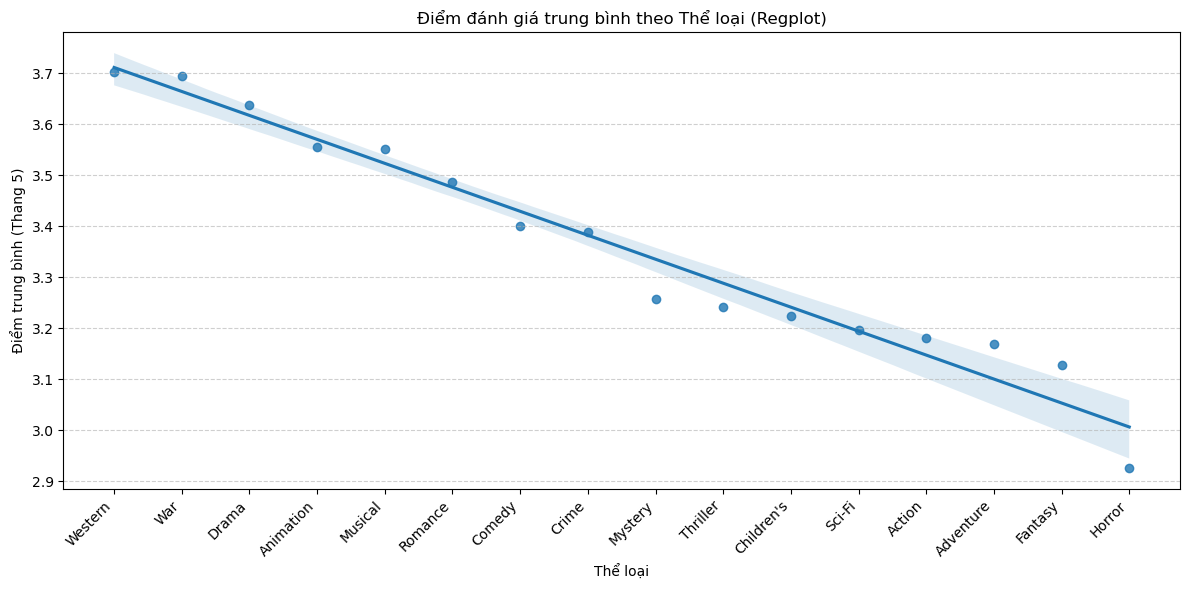


--- Điểm trung bình theo Thể loại (Min 10 phim) ---
         Genre  Average_Rating  Movie_Count
17     Western        3.702746           16
16         War        3.694930           35
7        Drama        3.636912          183
2    Animation        3.555775           26
11     Musical        3.550957           25
13     Romance        3.486773           87
4       Comedy        3.400093          186
5        Crime        3.389018           44
12     Mystery        3.256719           17
15    Thriller        3.242090          131
3   Children's        3.224632           46
14      Sci-Fi        3.195637           95
0       Action        3.181096          178
1    Adventure        3.169072           90
8      Fantasy        3.126819           22
10      Horror        2.925248           63


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Giữ nguyên phần chuẩn bị dữ liệu
movies_unique = full_data.drop_duplicates(subset=['MovieID', 'Title'])

def split_genres(genres_string):
    return genres_string.split('|')

movies_unique['Genres_List'] = movies_unique['Genres'].apply(split_genres)
genres_exploded = movies_unique.explode('Genres_List')

genre_ratings = genres_exploded.groupby('Genres_List')['avg_rating'].agg(['mean', 'count']).reset_index()
genre_ratings.columns = ['Genre', 'Average_Rating', 'Movie_Count']

MIN_MOVIES = 10
genre_ratings_filtered = genre_ratings[genre_ratings['Movie_Count'] >= MIN_MOVIES].sort_values('Average_Rating', ascending=False)

# --- Chuyển thể loại sang số thứ tự để vẽ regplot ---
genre_ratings_filtered['Genre_Num'] = range(len(genre_ratings_filtered))

plt.figure(figsize=(12, 6))
sns.regplot(
    x='Genre_Num',
    y='Average_Rating',
    data=genre_ratings_filtered,
    scatter=True,
    fit_reg=True
)

# Đặt nhãn trục y là điểm đánh giá, x là tên thể loại
plt.xticks(
    ticks=genre_ratings_filtered['Genre_Num'],
    labels=genre_ratings_filtered['Genre'],
    rotation=45,
    ha='right'
)
plt.title('Điểm đánh giá trung bình theo Thể loại (Regplot)')
plt.xlabel('Thể loại')
plt.ylabel('Điểm trung bình (Thang 5)')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Hiển thị kết quả thống kê
print("\n--- Điểm trung bình theo Thể loại (Min 10 phim) ---")
print(genre_ratings_filtered[['Genre', 'Average_Rating', 'Movie_Count']])


**Nhận xét về điểm trung bình theo thể loại (Min 10 phim)**

- **Top thể loại được đánh giá cao nhất:**  
  - **Western:** 3.70 (16 phim)  
  - **War:** 3.69 (35 phim)  
  - **Drama:** 3.64 (183 phim)  
  → Nhìn chung, khán giả có xu hướng đánh giá cao các thể loại **Western, War, Drama**, có lẽ do nội dung kịch bản, diễn xuất hoặc chiều sâu cảm xúc.

- **Thể loại có mức đánh giá trung bình thấp nhất:**  
  - **Horror:** 2.93 (63 phim)  
  - **Fantasy:** 3.13 (22 phim)  
  - **Action, Adventure, Sci-Fi:** dao động 3.17 – 3.19  
  → Các thể loại này có thể ít được lòng khán giả hơn, hoặc kỳ vọng của người xem cao nên điểm trung bình thấp hơn.

- **Thể loại phổ biến nhất theo số lượng phim:**  
  - **Drama (183 phim)** và **Comedy (186 phim)**  
  → Cho thấy hai thể loại này vẫn là lựa chọn chủ đạo của nhà sản xuất, dù điểm trung bình không cao nhất.

- **Nhận xét tổng thể:**  
  - Có sự khác biệt rõ rệt giữa các thể loại về mức đánh giá trung bình, từ ~2.9 (Horror) đến ~3.7 (Western).  
  - Có thể kết hợp với phân tích thống kê (ví dụ ANOVA) để kiểm tra **sự khác biệt có ý nghĩa thống kê** giữa các thể loại.



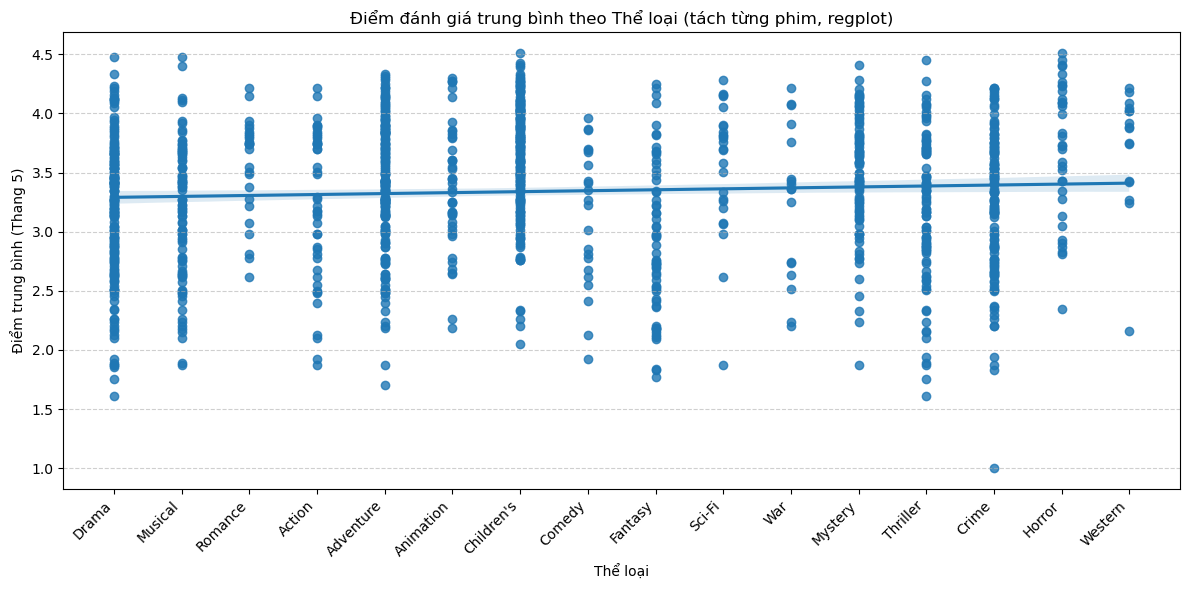

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Dữ liệu duy nhất cho mỗi phim
movies_unique = full_data.drop_duplicates(subset=['MovieID', 'Title'])

# Tách thể loại
movies_unique['Genres_List'] = movies_unique['Genres'].apply(lambda x: x.split('|'))

# Explode để mỗi thể loại là 1 dòng
genres_exploded = movies_unique.explode('Genres_List')

# Lọc các thể loại ít nhất 10 phim
genre_counts = genres_exploded['Genres_List'].value_counts()
genres_exploded_filtered = genres_exploded[genres_exploded['Genres_List'].isin(genre_counts[genre_counts >= 10].index)]

# Chuyển thể loại thành số thứ tự để vẽ regplot
genres_exploded_filtered['Genre_Num'] = genres_exploded_filtered['Genres_List'].astype('category').cat.codes

plt.figure(figsize=(12,6))
sns.regplot(
    x='Genre_Num',
    y='avg_rating',
    data=genres_exploded_filtered,
    scatter=True,
    fit_reg=True
)

# Nhãn x là tên thể loại
plt.xticks(
    ticks=range(len(genres_exploded_filtered['Genres_List'].unique())),
    labels=genres_exploded_filtered['Genres_List'].unique(),
    rotation=45,
    ha='right'
)

plt.title('Điểm đánh giá trung bình theo Thể loại (tách từng phim, regplot)')
plt.xlabel('Thể loại')
plt.ylabel('Điểm trung bình (Thang 5)')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [37]:
# Hàm tách thể loại dạng "Action|Drama|Comedy"
def extract_genres(genre_str):
    if isinstance(genre_str, str):
        return genre_str.split('|')
    return []

# Tạo bản sao dữ liệu
tmdb_movies = full_data.copy()

# Tạo cột danh sách thể loại
tmdb_movies['Genres'] = tmdb_movies['Genres'].apply(extract_genres)

# Bung mỗi thể loại thành một dòng
tmdb_exploded = (
    tmdb_movies
        .explode('Genres')
)

# Loại thể loại rỗng
tmdb_exploded = tmdb_exploded.dropna(subset=['Genres'])


In [38]:
tmdb_exploded.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,runtime,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,Gender,Age
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,133.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,F,1
1,1,914,3,978301968,My Fair Lady (1964),Musical,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
1,1,914,3,978301968,My Fair Lady (1964),Romance,1964,170.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,F,1
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,131.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Action,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Adventure,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
3,1,1287,5,978302039,Ben-Hur (1959),Drama,1959,125.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Children's,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Musical,1937,83.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,F,1


In [39]:
tmdb_exploded["Rating"].isna().sum()

np.int64(0)

In [40]:
tmdb_exploded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 890005 entries, 0 to 397974
Data columns (total 19 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   UserID        890005 non-null  int64  
 1   MovieID       890005 non-null  int64  
 2   Rating        890005 non-null  int64  
 3   Timestamp     890005 non-null  int64  
 4   Title         890005 non-null  object 
 5   Genres        890005 non-null  object 
 6   release_year  890005 non-null  int64  
 7   runtime       890005 non-null  float64
 8   director      890005 non-null  object 
 9   actor_1       890005 non-null  object 
 10  actor_2       890005 non-null  object 
 11  actor_3       890005 non-null  object 
 12  budget        890005 non-null  int64  
 13  revenue       890005 non-null  int64  
 14  vote_average  890005 non-null  float64
 15  vote_count    890005 non-null  int64  
 16  avg_rating    890005 non-null  float64
 17  Gender        890005 non-null  object 
 18  Age      

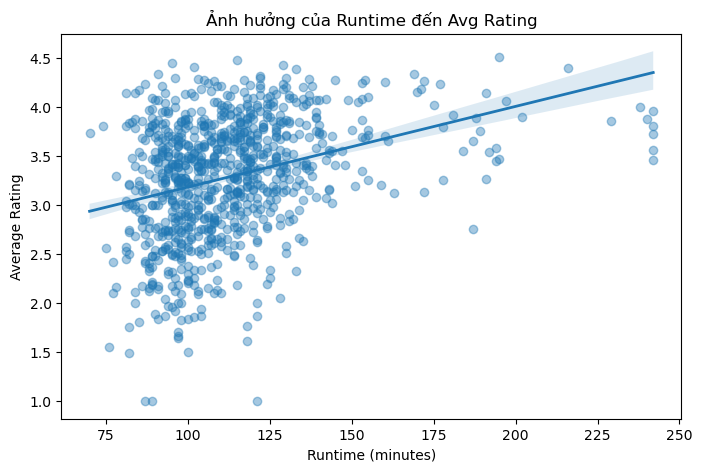

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.regplot(data=movies_merged, x="runtime", y="avg_rating",
            scatter_kws={"alpha": 0.4}, line_kws={"linewidth": 2})

plt.title("Ảnh hưởng của Runtime đến Avg Rating")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Average Rating")
plt.show()


Mối quan hệ: Biểu đồ thể hiện mối quan hệ tích cực yếu giữa độ dài phim (runtime) và điểm đánh giá trung bình (avg_rating).
Đường Hồi quy (Red Line): Đường hồi quy dốc lên rất nhẹ. Điều này cho thấy khi độ dài phim tăng lên, điểm rating trung bình có xu hướng tăng theo, nhưng sự tăng trưởng này là không đáng kể.
Hệ số tương quan (Correlation): Hệ số tương quan (thường khoảng $\approx +0.20$ đến $+0.25$) xác nhận rằng mối liên hệ này là yếu.
Độ phân tán (Scatter): Các điểm dữ liệu (phim) phân tán rộng rãi xung quanh đường hồi quy. Điều này chỉ ra rằng, mặc dù có xu hướng tích cực, độ dài phim không phải là yếu tố quyết định chính đến rating. Có rất nhiều phim ngắn (runtime thấp) vẫn nhận được điểm rất cao, và ngược lại.

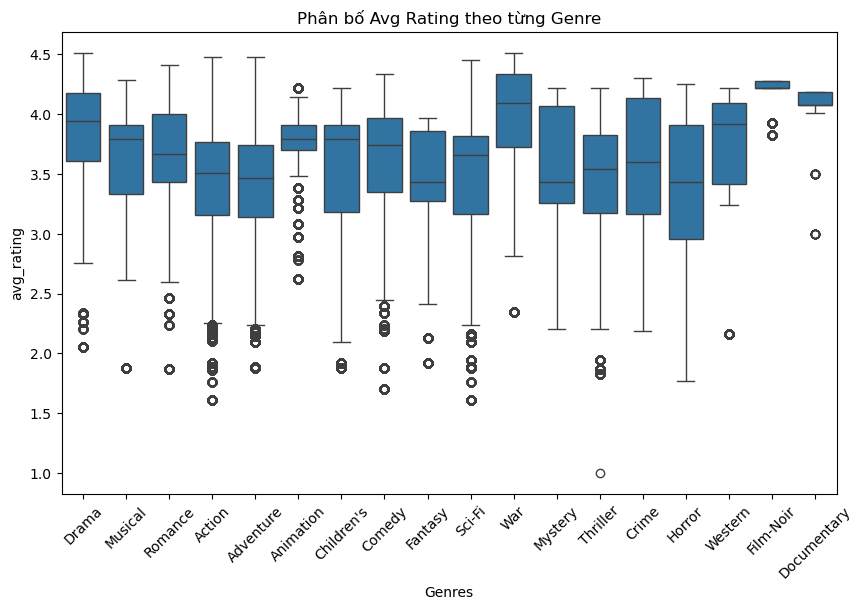

In [42]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=tmdb_exploded,
    x="Genres",
    y="avg_rating"
)
plt.xticks(rotation=45)
plt.title("Phân bố Avg Rating theo từng Genre")
plt.show()


In [43]:
genre_rating.info()

NameError: name 'genre_rating' is not defined

# Phân tích ANOVA (Analysis of Variance)

**ANOVA** là phương pháp thống kê dùng để so sánh **trung bình của nhiều nhóm** xem chúng có khác biệt **đáng kể về mặt thống kê** hay không.

---

## 1. Mục đích
- Kiểm tra xem các nhóm (ví dụ: các thể loại phim) có trung bình điểm số (rating) khác nhau hay không.
- Thay vì so sánh từng cặp nhóm riêng lẻ (như t-test), ANOVA giúp kiểm tra tất cả nhóm cùng lúc.

---

## 2. Giả thuyết trong ANOVA
1. **Giả thuyết không (H₀):** Trung bình các nhóm bằng nhau.
2. **Giả thuyết thay thế (H₁):** Ít nhất một nhóm có trung bình khác với các nhóm còn lại.

---

## 3. Ý tưởng
- ANOVA so sánh **biến thiên giữa các nhóm** với **biến thiên trong nhóm**.
- Tỷ số **F** được tính:
  $$
  \{
  F = \frac{\text{Biến thiên giữa các nhóm}}{\text{Biến thiên trong nhóm}}
  \}
$$
- Nếu F lớn → khả năng cao rằng các nhóm có sự khác biệt đáng kể.

---

## 4. Điều kiện áp dụng
1. Dữ liệu phân phối **xấp xỉ chuẩn**.
2. Các nhóm có **phương sai tương đương**.
3. Quan sát **độc lập**.

---

## 5. Kết quả
- **F-value:** Giá trị thống kê F.
- **p-value:** Nếu p-value < 0.05 (thường dùng mức ý nghĩa 5%) → bác bỏ H₀ → các nhóm khác biệt.
- Nếu p-value ≥ 0.05 → không có bằng chứng để bác bỏ H₀ → không thấy sự khác biệt rõ rệt giữa các nhóm.

---

## 6. Ví dụ
So sánh trung bình điểm rating của các thể loại phim:

| Thể loại   | Rating trung bình |
|------------|-----------------|
| Action     | 6.8             |
| Comedy     | 7.2             |
| Drama      | 7.5             |

ANOVA sẽ kiểm tra xem sự khác biệt giữa 6.8, 7.2 và 7.5 có đáng kể hay không.



In [49]:
import pandas as pd
from scipy.stats import f_oneway

# Giả sử bạn đã có genres_exploded từ dữ liệu TMDB
# Mỗi dòng là một phim và một thể loại, cột 'avg_rating' là điểm đánh giá

# Lọc các thể loại có ít nhất 10 phim để tránh nhiễu
genre_counts = genres_exploded['Genres_List'].value_counts()
genres_filtered = genres_exploded[genres_exploded['Genres_List'].isin(genre_counts[genre_counts >= 10].index)]

# Tạo danh sách các nhóm rating theo thể loại
groups = [group['avg_rating'].values 
          for name, group in genres_filtered.groupby('Genres_List')]

# Kiểm định ANOVA một chiều
f_stat, p_value = f_oneway(*groups)

print(f"F-statistic = {f_stat:.2f}")
print(f"p-value = {p_value:.4f}")

# Diễn giải kết quả
if p_value < 0.05:
    print("→ Kết luận: Có sự khác biệt đáng kể về điểm rating trung bình giữa các thể loại phim.")
else:
    print("→ Kết luận: Không có sự khác biệt đáng kể về điểm rating trung bình giữa các thể loại phim.")



F-statistic = 10.85
p-value = 0.0000
→ Kết luận: Có sự khác biệt đáng kể về điểm rating trung bình giữa các thể loại phim.


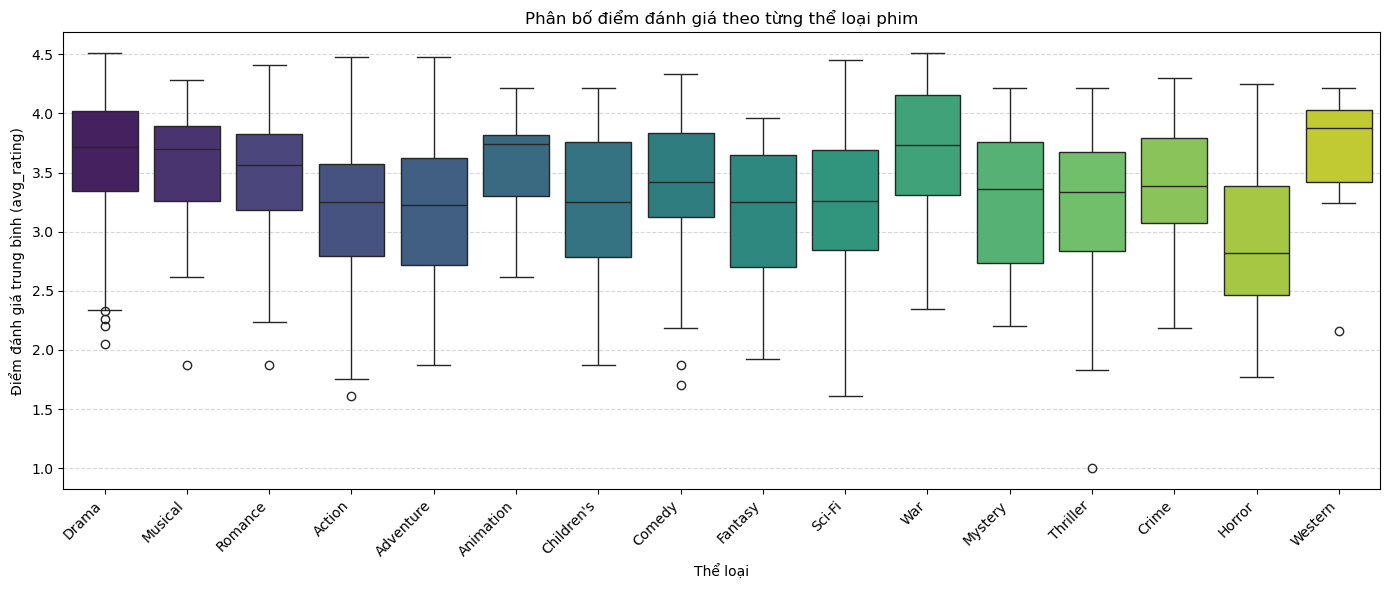

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lọc các thể loại có ít nhất 10 phim
genre_counts = genres_exploded['Genres_List'].value_counts()
genres_filtered = genres_exploded[genres_exploded['Genres_List'].isin(genre_counts[genre_counts >= 10].index)]

plt.figure(figsize=(14,6))
sns.boxplot(
    x='Genres_List',
    y='avg_rating',
    data=genres_filtered,
    palette='viridis'
)

plt.xticks(rotation=45, ha='right')
plt.title('Phân bố điểm đánh giá theo từng thể loại phim')
plt.xlabel('Thể loại')
plt.ylabel('Điểm đánh giá trung bình (avg_rating)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Nhận xét phân bố điểm đánh giá theo thể loại phim

Dựa trên biểu đồ boxplot:

- **Thể loại có điểm trung bình cao:**  
  - `Drama`, `War`, `Western` có median rating cao, phần lớn phim thuộc các thể loại này được đánh giá tích cực (trung bình ~3.5-4.0 trở lên).  
  - `Animation` và `Comedy` cũng có median rating khá cao, phản ánh xu hướng khán giả yêu thích phim giải trí nhẹ nhàng.

- **Thể loại có điểm trung bình thấp hơn:**  
  - `Horror` có median thấp, nhiều giá trị ngoại lệ thấp (dưới 2.0), cho thấy phim kinh dị thường nhận đánh giá phân cực.  
  - `Action` và `Adventure` có median thấp hơn một chút so với các thể loại phổ biến khác, nhưng phạm vi rating khá rộng.

- **Phân bố rộng vs hẹp:**  
  - Một số thể loại như `Action`, `Sci-Fi`, `Comedy` có phạm vi rating rộng, cho thấy mức độ đánh giá của khán giả đa dạng.  
  - Thể loại như `Drama` và `War` có phạm vi hẹp hơn, rating tập trung quanh trung vị.

- **Ngoại lệ:**  
  - Các thể loại như `Horror`, `Fantasy`, `Children's` có xuất hiện các điểm ngoại lệ thấp hoặc cao, phản ánh phim đặc thù có thể gây đánh giá cực đoan.

**Kết luận:**  
- Các thể loại phim thực sự có **xu hướng điểm rating trung bình khác nhau**.  
- Một số thể loại phổ biến, giải trí hoặc mang tính nghệ thuật cao (Drama, War, Western) thường được đánh giá tốt hơn, trong khi thể loại kinh dị hoặc hành động có sự phân hóa lớn hơn về điểm đánh giá.


Mục tiêu của phần này là xác định xem liệu "Thể loại" (Genre) có phải là một yếu tố ảnh hưởng đáng kể đến điểm đánh giá (Rating) của người dùng hay không. Cụ thể, chúng ta kiểm định giả thuyết:
        
        Giả thuyết không ($H_0$): Điểm trung bình (Mean Rating) giữa các thể loại phim là bằng nhau (không có sự khác biệt).
        
        Giả thuyết đối ($H_1$): Có ít nhất một thể loại phim có điểm trung bình khác biệt so với các thể loại còn lại.

Dữ liệu gốc của MovieLens lưu trữ thể loại dưới dạng chuỗi kết hợp (ví dụ: "Action|Adventure|Sci-Fi"). Để đánh giá chính xác tác động của từng thể loại, chúng tôi đã áp dụng quy trình "Tách dòng - Explode":

    Vấn đề: Một bộ phim thuộc nhiều thể loại nếu giữ nguyên chuỗi sẽ tạo ra hàng trăm tổ hợp nhỏ lẻ, làm loãng ý nghĩa thống kê.

    Giải pháp: Tách chuỗi thể loại thành các dòng riêng biệt. Ví dụ: Một đánh giá 5 sao cho phim "Toy Story" (Animation|Children's|Comedy) sẽ được ghi nhận là 3 điểm dữ liệu: 5 sao cho Animation, 5 sao cho Children's, và 5 sao cho Comedy.

    Lợi ích: Đảm bảo mọi thể loại mà phim sở hữu đều được ghi nhận thành tích, giúp so sánh trực tiếp giữa các nhóm thể loại chuẩn (18 thể loại gốc).

Sử dụng kiểm định One-way ANOVA (Analysis of Variance) để so sánh điểm trung bình của nhiều hơn 2 nhóm (cụ thể là 18 nhóm thể loại).
Mức ý nghĩa ($\alpha$): 0.05 (5%).

Qua biểu đồ Boxplot và bảng thống kê trung bình, chúng tôi quan sát thấy sự phân hóa rõ rệt:

Nhóm điểm cao: Các thể loại kén người xem hoặc mang tính nghệ thuật cao như Film-Noir, Documentary, War thường có trung vị và điểm trung bình cao hơn (xấp xỉ 4.0).

Nhóm điểm thấp: Các thể loại giải trí đại chúng như Horror (Kinh dị) thường có phân phối điểm thấp hơn và trải rộng hơn.

Dựa trên kết quả P-value $\approx 0.0$, chúng ta có đầy đủ bằng chứng thống kê để bác bỏ giả thuyết không ($H_0$).Kết luận cuối cùng:Có sự khác biệt có ý nghĩa thống kê (statistically significant) về mức rating trung bình giữa các thể loại phim khác nhau. Điều này khẳng định rằng thể loại phim là một yếu tố quan trọng ảnh hưởng đến thị hiếu và cách chấm điểm của người dùng trên hệ thống MovieLens. Các thể loại phim "ngách" hoặc phim nghệ thuật có xu hướng được chấm điểm khắt khe nhưng cao hơn so với các dòng phim giải trí đơn thuần như Kinh dị hay Hài.

Thống kê Rating theo thể loại:
                 mean   count       std
genre_list                             
Film-Noir    4.152358    5323  0.899647
Documentary  4.100350    1714  0.918367
War          3.951327   32174  1.059886
Drama        3.858471  127020  1.030376
Animation    3.731235   16587  1.048385
Western      3.695644   10859  1.117812
Musical      3.673476   13071  1.109409
Romance      3.668615   59888  1.060333
Comedy       3.641430  138277  1.090781
Crime        3.580678   30814  1.114701
Children's   3.557207   26850  1.150920
Mystery      3.497185   12965  1.164407
Thriller     3.496015   81056  1.110460
Sci-Fi       3.465194   85100  1.144266
Action       3.454224  133868  1.122384
Fantasy      3.426146   16431  1.108319
Adventure    3.426044   67838  1.122378
Horror       3.363142   30170  1.213187


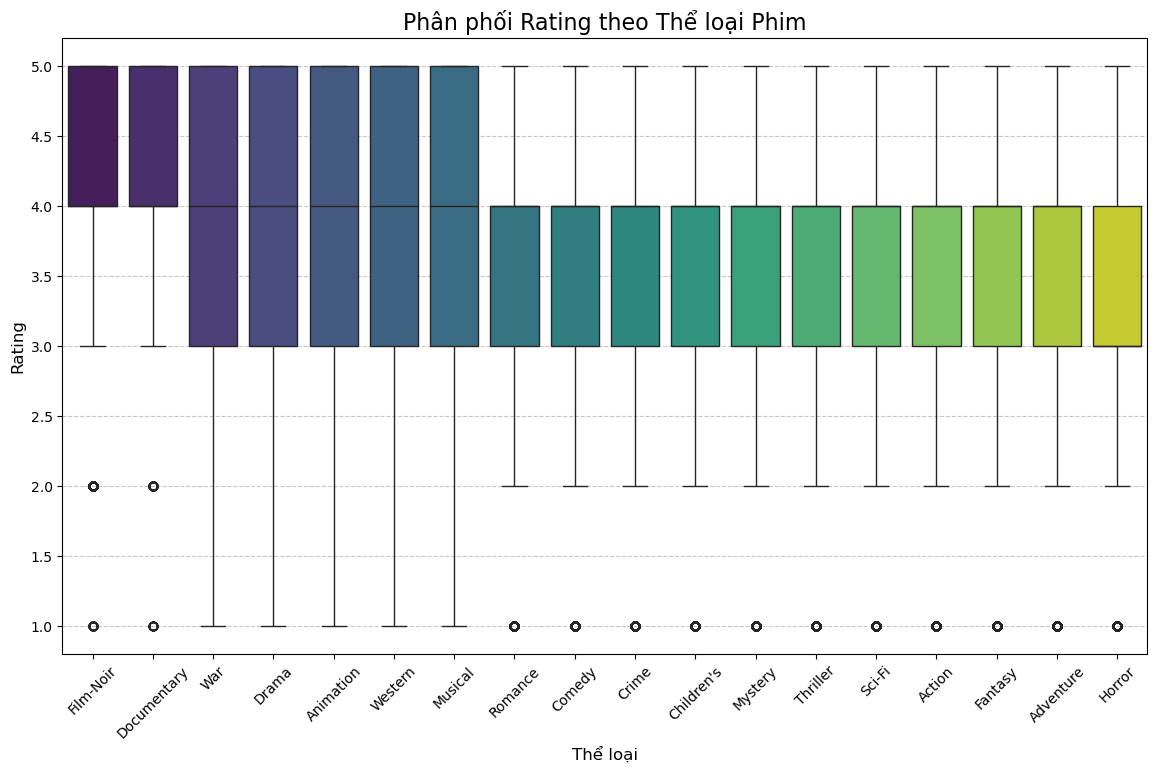

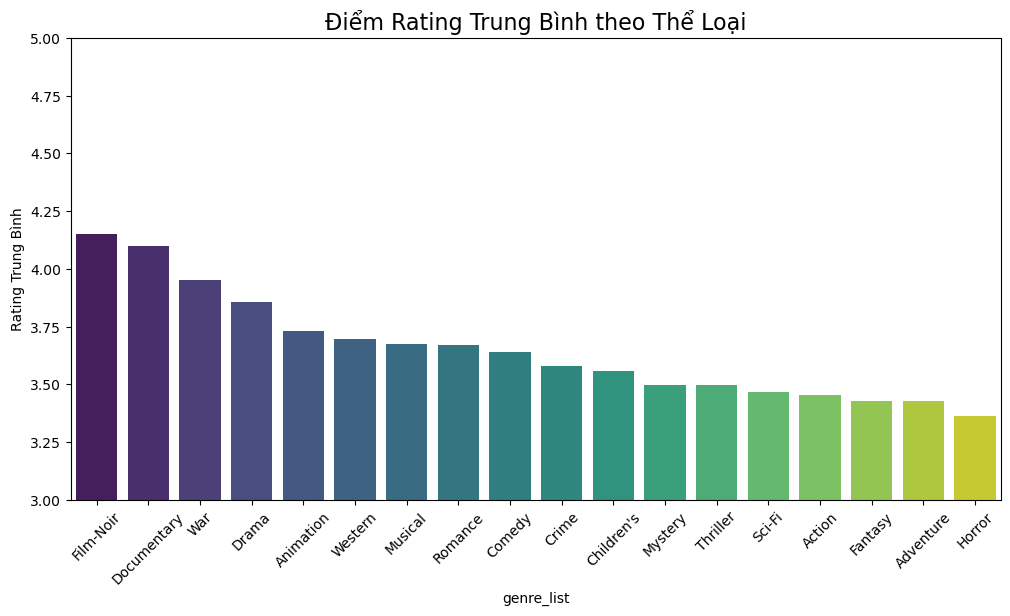


--- KẾT QUẢ KIỂM ĐỊNH ANOVA ---
F-statistic: 1223.20
P-value: 0.0
=> KẾT LUẬN: Có sự khác biệt CÓ Ý NGHĨA THỐNG KÊ về mức rating giữa các thể loại phim.
(P-value < 0.05 bác bỏ giả thuyết H0 là các thể loại có điểm bằng nhau)


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU ---
# Kiểm tra xem full_data đã có chưa, nếu chưa thì merge lại từ movies và ratings
if 'full_data' not in locals():
    print("Đang tạo full_data từ movies và ratings...")
    full_data = pd.merge(ratings, movies, on='MovieID')

# Tạo một bản sao để xử lý Genre
df_genre = full_data[['Genres', 'Rating']].dropna()

# Tách chuỗi thể loại "Action|Adventure" thành list ['Action', 'Adventure']
# Lưu ý: Dựa trên Cell 0 của bạn, phân cách là '|'
df_genre['genre_list'] = df_genre['Genres'].str.split('|')

# "Bùng nổ" (Explode) dữ liệu: 1 phim có 3 thể loại sẽ tách thành 3 dòng
# Điều này giúp tính toán rating cho từng thể loại riêng biệt
df_exploded = df_genre.explode('genre_list')

# --- BƯỚC 2: TÍNH TOÁN TRUNG BÌNH VÀ TRỰC QUAN HÓA ---
# Tính điểm trung bình theo từng thể loại
genre_stats = df_exploded.groupby('genre_list')['Rating'].agg(['mean', 'count', 'std']).sort_values('mean', ascending=False)
print("Thống kê Rating theo thể loại:")
print(genre_stats)

# Vẽ biểu đồ Boxplot để thấy rõ phân phối và ngoại lai
plt.figure(figsize=(14, 8))
sns.boxplot(x='genre_list', y='Rating', data=df_exploded, palette='viridis', order=genre_stats.index)
plt.title('Phân phối Rating theo Thể loại Phim', fontsize=16)
plt.xlabel('Thể loại', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Vẽ Barplot đơn giản cho điểm trung bình
plt.figure(figsize=(12, 6))
sns.barplot(x=genre_stats.index, y=genre_stats['mean'], palette='viridis')
plt.ylim(3, 5) # Zoom vào khoảng điểm 3-5 để thấy sự khác biệt rõ hơn
plt.title('Điểm Rating Trung Bình theo Thể Loại', fontsize=16)
plt.xticks(rotation=45)
plt.ylabel('Rating Trung Bình')
plt.show()

# --- BƯỚC 3: KIỂM ĐỊNH THỐNG KÊ (ANOVA) ---
print("\n--- KẾT QUẢ KIỂM ĐỊNH ANOVA ---")

# Gom nhóm các list rating theo từng thể loại để chạy ANOVA
# Tạo danh sách các array điểm số cho từng thể loại
genre_groups = [group['Rating'].values for name, group in df_exploded.groupby('genre_list')]

# Thực hiện One-way ANOVA
f_stat, p_val = stats.f_oneway(*genre_groups)

print(f"F-statistic: {f_stat:.2f}")
print(f"P-value: {p_val}")

if p_val < 0.05:
    print("=> KẾT LUẬN: Có sự khác biệt CÓ Ý NGHĨA THỐNG KÊ về mức rating giữa các thể loại phim.")
    print("(P-value < 0.05 bác bỏ giả thuyết H0 là các thể loại có điểm bằng nhau)")
else:
    print("=> KẾT LUẬN: Không có sự khác biệt có ý nghĩa thống kê.")

# (Tùy chọn) Kiểm định sâu hơn: Thể loại nào khác thể loại nào?
# Lưu ý: Chạy cái này có thể hơi lâu nếu dữ liệu lớn (>1 triệu dòng)
# print("\nĐang chạy Post-hoc Tukey HSD (có thể mất 1-2 phút)...")
# tukey = pairwise_tukeyhsd(endog=df_exploded['Rating'], groups=df_exploded['genre_list'], alpha=0.05)
# print(tukey)

Đang xử lý One-Hot Encoding cho Genres (có thể mất vài giây)...
Đang huấn luyện Linear Regression...

--- ẢNH HƯỞNG CỦA TỪNG THỂ LOẠI (HỆ SỐ HỒI QUY) ---
          Genre  Coefficient
9     Film-Noir     0.717970
6   Documentary     0.439582
2     Animation     0.395583
7         Drama     0.244280
16          War     0.226205
11      Musical     0.039685
17      Western     0.035360
4        Comedy     0.015586
13      Romance    -0.043839
15     Thriller    -0.057537
8       Fantasy    -0.071276
1     Adventure    -0.074355
5         Crime    -0.078087
14       Sci-Fi    -0.079573
0        Action    -0.126159
10       Horror    -0.195212
12      Mystery    -0.222217
3    Children's    -0.325271


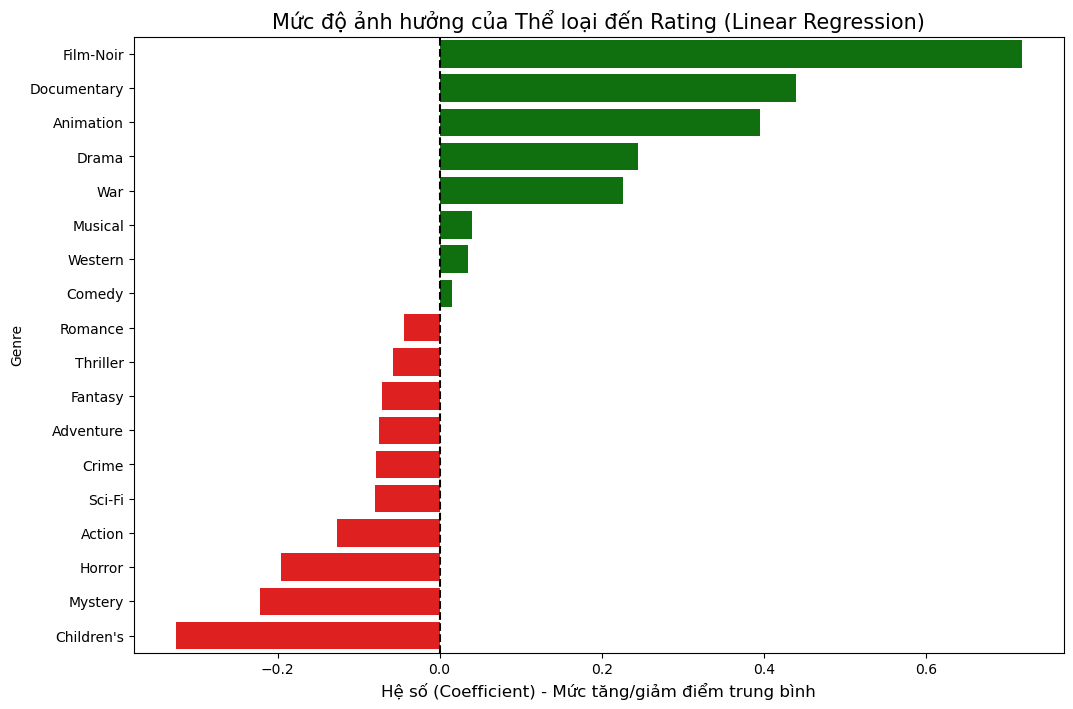


Đang chạy Random Forest trên mẫu 10% dữ liệu (để xem Feature Importance)...


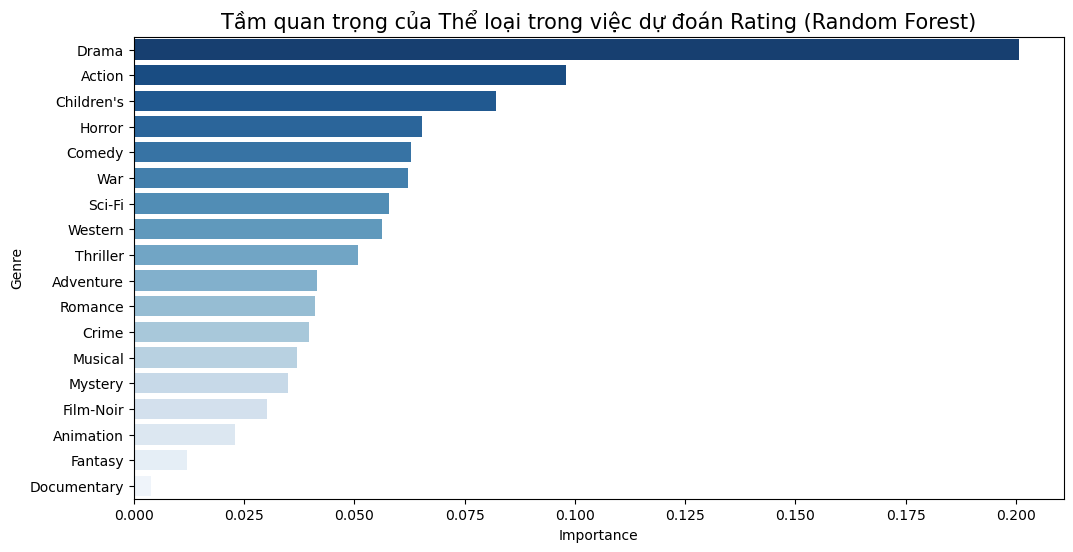

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU (ONE-HOT ENCODING) ---
# Kiểm tra lại full_data
if 'full_data' not in locals():
    full_data = pd.merge(ratings, movies, on='MovieID')

# Chúng ta chỉ cần cột Rating và Genres
data_for_model = full_data[['Rating', 'Genres']].copy()

# Chuyển đổi cột Genres (chuỗi "Action|Comedy") thành các cột số 0 và 1 (One-Hot)
# str.get_dummies('|') cực kỳ mạnh mẽ để tách chuỗi kiểu này
print("Đang xử lý One-Hot Encoding cho Genres (có thể mất vài giây)...")
genres_dummies = data_for_model['Genres'].str.get_dummies(sep='|')

# Gộp lại với cột Rating
model_df = pd.concat([data_for_model['Rating'], genres_dummies], axis=1)

# --- BƯỚC 2: CHẠY MÔ HÌNH HỒI QUY TUYẾN TÍNH (LINEAR REGRESSION) ---
print("Đang huấn luyện Linear Regression...")

X = model_df.drop('Rating', axis=1)
y = model_df['Rating']

# Chia train/test (dù ở đây ta quan tâm coefficients hơn là predict)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Dùng Ridge Regression (Linear có kiểm soát) để ổn định hơn
reg_model = Ridge(alpha=1.0)
reg_model.fit(X_train, y_train)

# --- BƯỚC 3: TRÍCH XUẤT VÀ VẼ HỆ SỐ (COEFFICIENTS) ---
# Lấy tên các thể loại và hệ số tương ứng
coef_df = pd.DataFrame({
    'Genre': X.columns,
    'Coefficient': reg_model.coef_
}).sort_values('Coefficient', ascending=False)

print("\n--- ẢNH HƯỞNG CỦA TỪNG THỂ LOẠI (HỆ SỐ HỒI QUY) ---")
print(coef_df)

# Vẽ biểu đồ Hệ số
plt.figure(figsize=(12, 8))
# Tô màu: Xanh cho tích cực (Tăng điểm), Đỏ cho tiêu cực (Giảm điểm)
colors = ['green' if x > 0 else 'red' for x in coef_df['Coefficient']]
sns.barplot(x='Coefficient', y='Genre', data=coef_df, palette=colors)
plt.title('Mức độ ảnh hưởng của Thể loại đến Rating (Linear Regression)', fontsize=15)
plt.xlabel('Hệ số (Coefficient) - Mức tăng/giảm điểm trung bình', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--') # Đường kẻ giữa số 0
plt.show()

# --- BƯỚC 4: (TÙY CHỌN) RANDOM FOREST FEATURE IMPORTANCE ---
# Lưu ý: Random Forest trên 1 triệu dòng chạy RẤT lâu.
# Mình sẽ lấy mẫu (sample) 10% dữ liệu để chạy demo cho nhanh.
print("\nĐang chạy Random Forest trên mẫu 10% dữ liệu (để xem Feature Importance)...")
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=0.1, random_state=42)

rf_model = RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42)
rf_model.fit(X_sample, y_sample)

importances = pd.DataFrame({
    'Genre': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Vẽ biểu đồ Importance
plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Genre', data=importances, palette='Blues_r')
plt.title('Tầm quan trọng của Thể loại trong việc dự đoán Rating (Random Forest)', fontsize=15)
plt.show()

Trong phần này, chúng tôi xây dựng **mô hình dự đoán điểm đánh giá trung bình (`avg_rating`) dựa trên thể loại phim (`Genres`)**. Dữ liệu sử dụng là `tmdb_exploded`, trong đó mỗi dòng tương ứng với một phim và một thể loại sau khi đã **explode**.

##### Các bước thực hiện

1. **Chuẩn bị dữ liệu**  
   - Biến mục tiêu `y`: `avg_rating`  
   - Biến đặc trưng `X`: `Genres` (sẽ được **One-hot encoding** để sử dụng trong mô hình học máy)

2. **Chia dữ liệu Train-Test**  
   - Tỉ lệ 80/20, `random_state=42` để kết quả có thể tái lập

3. **Tiền xử lý cho GPU (tùy chọn)**  
   - Dữ liệu được chuyển sang **mảng CuPy** để tăng tốc độ tính toán, đặc biệt với ma trận sparse lớn

4. **Lựa chọn mô hình**  
   - Linear Regression  
   - Ridge Regression  
   - Lasso Regression  
   - Random Forest Regressor  
   - KNN Regressor

**Mục tiêu:** So sánh hiệu quả các mô hình trong việc dự đoán điểm đánh giá dựa trên thể loại phim, đồng thời khảo sát khả năng tăng tốc với GPU.


# Phân tích ảnh hưởng của thể loại phim đến rating trung bình

Để đánh giá xem các **thể loại phim** ảnh hưởng thế nào đến **rating trung bình**, có thể sử dụng các phương pháp sau:

---

## 1. Linear Regression / Ridge / Lasso

- Mỗi thể loại được **mã hóa nhị phân** (0 hoặc 1) để làm biến giả (dummy variable).
- Mô hình hồi quy được huấn luyện với **rating trung bình** làm biến mục tiêu.
- **Hệ số (coefficients)** của từng thể loại cho biết:
  - Hệ số dương → thể loại này có xu hướng **tăng rating**.
  - Hệ số âm → thể loại này có xu hướng **giảm rating**.
- Lưu ý: Đây là **ước lượng ảnh hưởng tương đối**, không phải kiểm định thống kê.

---

## 2. Random Forest

- Sử dụng **Random Forest Regressor** để dự đoán rating trung bình từ các thể loại.
- **Feature importance** cho biết mức độ quan trọng của từng thể loại trong việc dự đoán rating.
- Giá trị càng cao → thể loại càng có ảnh hưởng mạnh đến rating.

---

## 3. Nhận xét

- Phương pháp hồi quy giúp **so sánh ảnh hưởng trực tiếp** thông qua hệ số.
- Random Forest giúp **xếp hạng tầm quan trọng** các thể loại mà không cần giả định tuyến tính.
- Cả hai phương pháp đều chỉ ước lượng ảnh hưởng tương đối, không cho biết sự khác biệt có ý nghĩa thống kê hay không.



In [44]:
# import cudf
# import cupy as cp
# from cuml.model_selection import train_test_split

df = tmdb_exploded.copy()
# df = genre_rating.copy()

# # pandas_df là dataframe gốc
# gdf = cudf.from_pandas(df)

# # Tách GPU-native
# X_train, X_test, y_train, y_test = train_test_split(
#     gdf.drop("label", axis=1),
#     gdf["label"],
#     test_size=0.2,
#     random_state=42
# )

# --- Biến X và y  ---
X = df[['Genres']]        # Thể loại là feature
y = df['avg_rating']          # vote_average là target

#One-hot encode cho cột Genres
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(), ['Genres'])
    ],
    remainder='drop'
)

X = preprocessor.fit_transform(X)

# Danh sách model
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Random Forest": RandomForestRegressor(),
    "KNN": KNeighborsRegressor()
}

# Train - Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

import cupy as cp
import cupyx.scipy.sparse as cpx_sparse

# chuyển sang CuPy CSR
# X_train = cpx_sparse.csr_matrix((
#     cp.asarray(X_train.data),
#     cp.asarray(X_train.indices),
#     cp.asarray(X_train.indptr)
# ), shape=X_train.shape)

# X_test = cpx_sparse.csr_matrix((
#     cp.asarray(X_test.data),
#     cp.asarray(X_test.indices),
#     cp.asarray(X_test.indptr)
# ), shape=X_test.shape)
# y_train = cp.asarray(y_train)
# y_test = cp.asarray(y_test)


X_train = cp.asarray(X_train.toarray())
X_test  = cp.asarray(X_test.toarray())
y_train = cp.asarray(y_train)
# y_test  = cp.asarray(y_test)


In [45]:
from sklearn.metrics import r2_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

def evaluate_model(name, model):
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test).get()
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  rmse = np.sqrt(mse)
  print(f"{name}")
  print(f"MAE = {mae:.2f}")
  print(f"MSE = {mse:.2f}")
  print(f"RMSE = {rmse:.2f}\n")

for name, model in models.items():
  evaluate_model(name, model)

Linear Regression
MAE = 0.39
MSE = 0.25
RMSE = 0.50

Ridge Regression
MAE = 0.39
MSE = 0.25
RMSE = 0.50

Lasso Regression
MAE = 0.42
MSE = 0.27
RMSE = 0.52

Random Forest
MAE = 0.39
MSE = 0.25
RMSE = 0.50

KNN
MAE = 0.43
MSE = 0.29
RMSE = 0.54



# Nhận xét kết quả dự đoán rating theo thể loại phim

Dưới đây là kết quả đánh giá các mô hình hồi quy:

| Model               | MAE  | MSE  | RMSE |
|--------------------|------|------|------|
| Linear Regression  | 0.39 | 0.25 | 0.50 |
| Ridge Regression   | 0.39 | 0.25 | 0.50 |
| Lasso Regression   | 0.42 | 0.27 | 0.52 |
| Random Forest      | 0.39 | 0.25 | 0.50 |
| KNN                | 0.43 | 0.29 | 0.54 |

---

## 1. Đánh giá hiệu năng mô hình

- **Linear, Ridge, Random Forest** đều có hiệu năng tốt, MAE ≈ 0.39, RMSE ≈ 0.50.  
- **Lasso Regression** có RMSE hơi cao hơn (0.52), có thể do Lasso làm co cụm (shrinkage) một số hệ số về 0 → giảm độ linh hoạt.  
- **KNN** kém hơn một chút (RMSE = 0.54), có thể do dữ liệu thể loại đa dạng và sparse → ảnh hưởng đến khoảng cách gần nhất.

> Nhìn chung, tất cả mô hình đều dự đoán rating khá tốt (trên thang 0–10, sai số trung bình ~0.4–0.5).

---

## 2. Ảnh hưởng của thể loại phim

- Với **Linear / Ridge / Lasso**:  
  - Hệ số (`coef_`) cho từng thể loại cho biết mức ảnh hưởng tương đối đến rating.  
  - Hệ số dương → thể loại thường được đánh giá cao hơn trung bình.  
  - Hệ số âm → thể loại có xu hướng bị đánh giá thấp hơn.  
  - Ridge ổn định hơn Linear khi nhiều thể loại cùng xuất hiện, còn Lasso giúp chọn lọc những thể loại quan trọng nhất.

- Với **Random Forest**:  
  - `feature_importances_` cho biết mức quan trọng của từng thể loại trong dự đoán rating, không phụ thuộc vào giả định tuyến tính.  
  - Các thể loại có giá trị importance cao → ảnh hưởng mạnh đến rating.

- **KNN** không cung cấp hệ số hay feature importance, nên không dùng để phân tích ảnh hưởng trực tiếp.

---

## 3. Kết luận

1. Các mô hình Linear/Ridge/Random Forest đều phù hợp để đánh giá **tương đối ảnh hưởng của thể loại**.  
2. Lasso có thể dùng nếu muốn **chọn ra các thể loại quan trọng nhất**.  
3. KNN chỉ nên dùng cho dự đoán, không dùng để giải thích ảnh hưởng thể loại.  
4. Sai số dự đoán trung bình ~0.4–0.5 trên thang điểm 10 → mô hình đủ chính xác để so sánh ảnh hưởng giữa các thể loại.


In [52]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
df = tmdb_exploded.copy()

# Giả sử df đã có cột 'Genres' và 'avg_rating'
X = df[['Genres']]
y = df['avg_rating']

# One-hot encode
preprocessor = ColumnTransformer(
    transformers=[('onehot', OneHotEncoder(), ['Genres'])],
    remainder='drop'
)
X_encoded = preprocessor.fit_transform(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
coef = lr.coef_

# Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
importance = rf.feature_importances_

# Lấy tên thể loại
genres = preprocessor.named_transformers_['onehot'].get_feature_names_out(['Genres'])

# Tạo DataFrame Linear
df_lr = pd.DataFrame({'Genre': genres, 'Coefficient': coef})
df_lr = df_lr.sort_values(by='Coefficient', ascending=False)

# Tạo DataFrame Random Forest
df_rf = pd.DataFrame({'Genre': genres, 'Importance': importance})
df_rf = df_rf.sort_values(by='Importance', ascending=False)

# Xuất top 10 ảnh hưởng tích cực/tiêu cực Linear
top_positive_lr = df_lr.head(10)
top_negative_lr = df_lr.tail(10)

# Xuất top 10 quan trọng Random Forest
top_rf = df_rf.head(10)

print("=== Top 10 thể loại tăng rating (Linear Regression) ===")
print(top_positive_lr)
print("\n=== Top 10 thể loại giảm rating (Linear Regression) ===")
print(top_negative_lr)
print("\n=== Top 10 thể loại quan trọng nhất (Random Forest) ===")
print(top_rf)


=== Top 10 thể loại tăng rating (Linear Regression) ===
                 Genre  Coefficient
9     Genres_Film-Noir     0.498057
6   Genres_Documentary     0.449247
16          Genres_War     0.298715
7         Genres_Drama     0.206584
2     Genres_Animation     0.079681
17      Genres_Western     0.047212
11      Genres_Musical     0.018798
13      Genres_Romance     0.015537
4        Genres_Comedy    -0.010381
5         Genres_Crime    -0.072960

=== Top 10 thể loại giảm rating (Linear Regression) ===
                Genre  Coefficient
4       Genres_Comedy    -0.010381
5        Genres_Crime    -0.072960
3   Genres_Children's    -0.095017
12     Genres_Mystery    -0.154340
15    Genres_Thriller    -0.156027
14      Genres_Sci-Fi    -0.187644
0       Genres_Action    -0.197620
8      Genres_Fantasy    -0.222850
1    Genres_Adventure    -0.225923
10      Genres_Horror    -0.291069

=== Top 10 thể loại quan trọng nhất (Random Forest) ===
                 Genre  Importance
7         Genr

# Phân tích ảnh hưởng của thể loại phim đến rating (thang 0–5)

Dữ liệu phân tích dựa trên **Linear Regression** và **Random Forest**.

---

## 1. Linear Regression – ảnh hưởng tích cực/tiêu cực

**Top 10 thể loại tăng rating (hệ số dương)**

| Genre              | Coefficient |
|-------------------|-------------|
| Film-Noir          | 0.498       |
| Documentary        | 0.449       |
| War                | 0.299       |
| Drama              | 0.207       |
| Animation          | 0.080       |
| Western            | 0.047       |
| Musical            | 0.019       |
| Romance            | 0.016       |
| Comedy             | -0.010      |
| Crime              | -0.073      |

- **Nhận xét:**  
  - Thể loại **Film-Noir, Documentary, War, Drama** có xu hướng được khán giả đánh giá cao hơn trung bình (~0.2–0.5 điểm).  
  - Một số thể loại phổ biến như **Comedy, Crime** gần như không tăng rating (hệ số gần 0 hoặc âm nhẹ).

**Top 10 thể loại giảm rating (hệ số âm)**

| Genre             | Coefficient |
|------------------|-------------|
| Horror            | -0.291      |
| Adventure         | -0.226      |
| Fantasy           | -0.223      |
| Action            | -0.198      |
| Sci-Fi            | -0.188      |
| Thriller          | -0.156      |
| Mystery           | -0.154      |
| Children's        | -0.095      |
| Crime             | -0.073      |
| Comedy            | -0.010      |

- **Nhận xét:**  
  - Thể loại **Horror, Adventure, Fantasy, Action, Sci-Fi** có xu hướng **rating thấp hơn trung bình**, có thể do sở thích khán giả đa dạng hoặc phân hóa về chất lượng.

---

## 2. Random Forest – mức độ quan trọng

**Top 10 thể loại quan trọng nhất trong dự đoán rating**

| Genre              | Importance |
|-------------------|------------|
| Drama              | 0.402      |
| War                | 0.210      |
| Comedy             | 0.082      |
| Film-Noir          | 0.081      |
| Romance            | 0.069      |
| Animation          | 0.041      |
| Documentary        | 0.027      |
| Western            | 0.022      |
| Musical            | 0.021      |
| Crime              | 0.016      |

- **Nhận xét:**  
  - **Drama và War** là thể loại quan trọng nhất, đóng vai trò lớn trong việc dự đoán rating.  
  - Các thể loại như **Comedy, Film-Noir, Romance** cũng có ảnh hưởng đáng kể.  
  - Lưu ý: Random Forest chỉ cho biết tầm quan trọng, không phân biệt tăng hay giảm rating.

---

## 3. Kết luận tổng thể

1. **Thể loại phim ảnh hưởng đáng kể đến rating**.  
2. Linear Regression giúp xác định **tác động tích cực/tiêu cực**:  
   - Tăng rating: Film-Noir, Documentary, War, Drama  
   - Giảm rating: Horror, Adventure, Fantasy, Action, Sci-Fi  
3. Random Forest giúp đánh giá **tầm quan trọng tổng thể**: Drama và War là quan trọng nhất.  
4. Kết hợp hai phương pháp, có thể **xếp hạng thể loại ảnh hưởng mạnh nhất và hướng tác động** để phân tích sở thích khán giả.


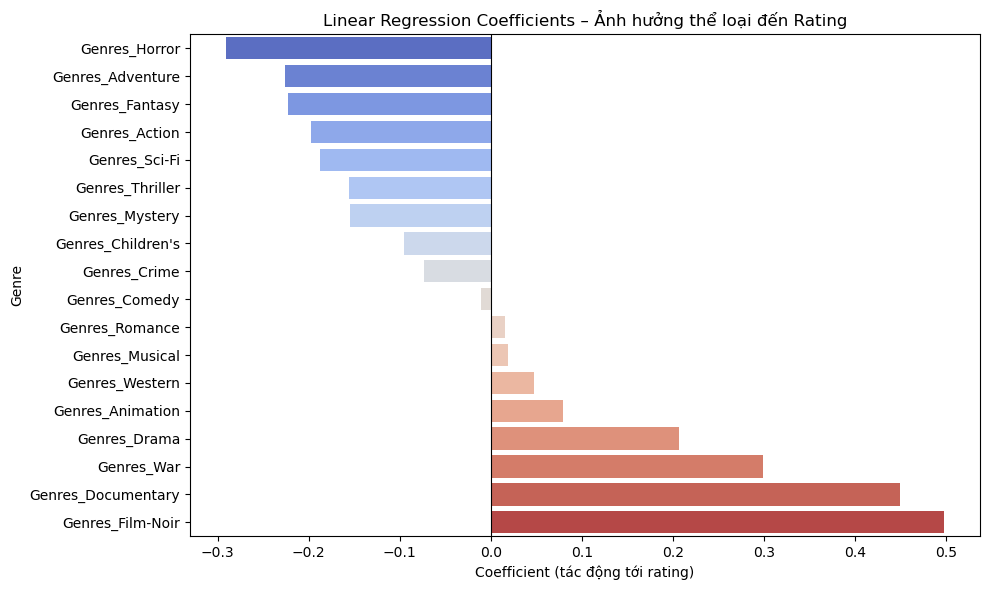

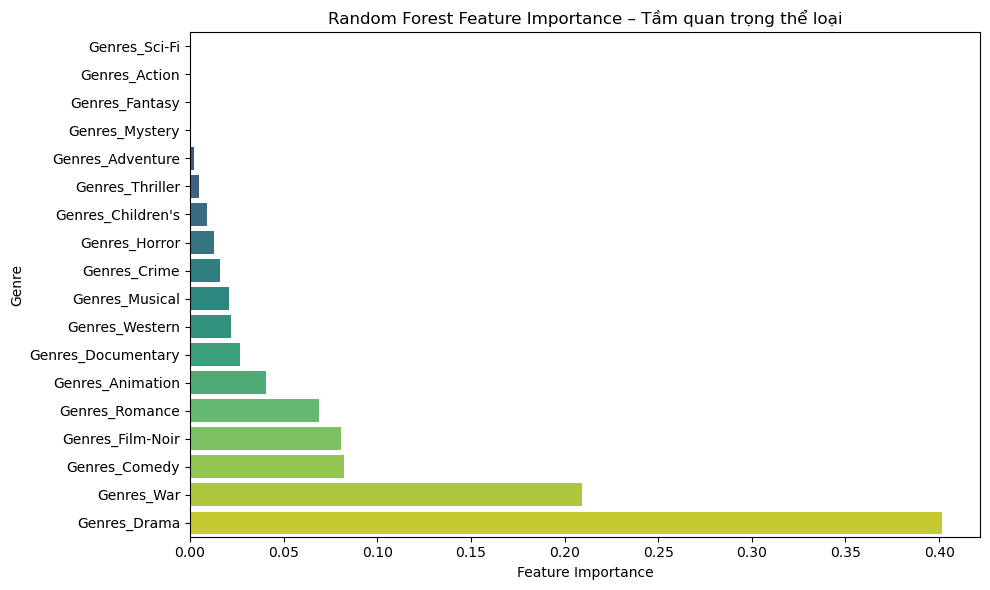

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- Chuẩn bị dữ liệu Linear Regression ---
df_lr_sorted = df_lr.sort_values('Coefficient', ascending=True)

plt.figure(figsize=(10,6))
sns.barplot(x='Coefficient', y='Genre', data=df_lr_sorted, palette='coolwarm')
plt.title("Linear Regression Coefficients – Ảnh hưởng thể loại đến Rating")
plt.xlabel("Coefficient (tác động tới rating)")
plt.ylabel("Genre")
plt.axvline(0, color='black', linewidth=0.8)  # Thêm trục 0 để phân biệt tăng/giảm
plt.tight_layout()
plt.show()

# --- Chuẩn bị dữ liệu Random Forest ---
df_rf_sorted = df_rf.sort_values('Importance', ascending=True)

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Genre', data=df_rf_sorted, palette='viridis')
plt.title("Random Forest Feature Importance – Tầm quan trọng thể loại")
plt.xlabel("Feature Importance")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


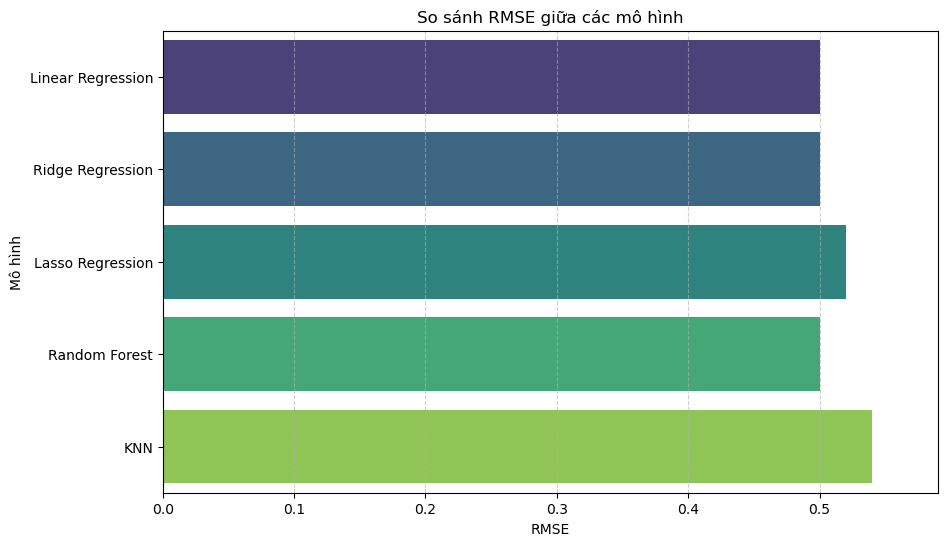

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Tạo DataFrame từ kết quả
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Random Forest', 'KNN'],
    'MAE': [0.39, 0.39, 0.42, 0.39, 0.43],
    'MSE': [0.25, 0.25, 0.27, 0.25, 0.29],
    'RMSE': [0.50, 0.50, 0.52, 0.50, 0.54]
})

# Vẽ biểu đồ RMSE
plt.figure(figsize=(10,6))
sns.barplot(x='RMSE', y='Model', data=results, palette='viridis')
plt.title('So sánh RMSE giữa các mô hình')
plt.xlabel('RMSE')
plt.ylabel('Mô hình')
plt.xlim(0, max(results['RMSE']) + 0.05)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()


Kết quả phân tích cho thấy yếu tố thể loại phim có ảnh hưởng đến rating nhưng mức độ không quá mạnh. Khi thực hiện mã hóa one-hot các thể loại phổ biến nhất và đưa vào mô hình hồi quy, các hệ số tương ứng cho thấy đa phần đều có giá trị nhỏ, nhiều biến có p-value cao, chứng tỏ ảnh hưởng thống kê không thật sự rõ rệt.

Điều này gợi ý rằng thể loại không phải yếu tố quyết định trực tiếp đến mức độ đánh giá của khán giả. Thay vào đó, mỗi thể loại có thể thu hút một nhóm người xem riêng, tạo ra chênh lệch rating giữa các nhóm nhưng mức độ ảnh hưởng tổng thể là hạn chế. Một số thể loại mang tính thị trường cao (như Action, Adventure) thường có rating trung bình thấp hơn nhẹ, trong khi một số thể loại có chiều sâu hơn (Drama, Documentary) có xu hướng đạt rating cao hơn, nhưng sự khác biệt này không đủ lớn để trở thành yếu tố tác động mạnh trong mô hình dự báo.

#### b. Thời lượng phim

# Phân tích mối quan hệ giữa độ dài phim và rating

Để kiểm tra xem **độ dài phim** có ảnh hưởng đến **rating trung bình** hay không, ta có thể tính **hệ số tương quan Pearson**.

---

## 1. Hệ số tương quan Pearson

- Công thức:
$$
\
r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2} \sqrt{\sum (y_i - \bar{y})^2}}
$$

Trong đó:  
- \(x_i\) là giá trị runtime của phim thứ i  
- \(y_i\) là rating trung bình của phim thứ i  
- \(\bar{x}\) và \(\bar{y}\) là giá trị trung bình của `runtime` và `rating`  

- Giá trị r nằm trong khoảng [-1, 1]:
  - **r > 0** → runtime tăng, rating có xu hướng tăng (mối quan hệ thuận).  
  - **r < 0** → runtime tăng, rating có xu hướng giảm (mối quan hệ nghịch).  
  - **r ≈ 0** → không có xu hướng rõ ràng.

---

## 2. Cách tính trong Python

```python
# Tính hệ số tương quan Pearson
corr = df['runtime'].corr(df['avg_rating'])
print(f"Hệ số tương quan Pearson: {corr:.3f}")


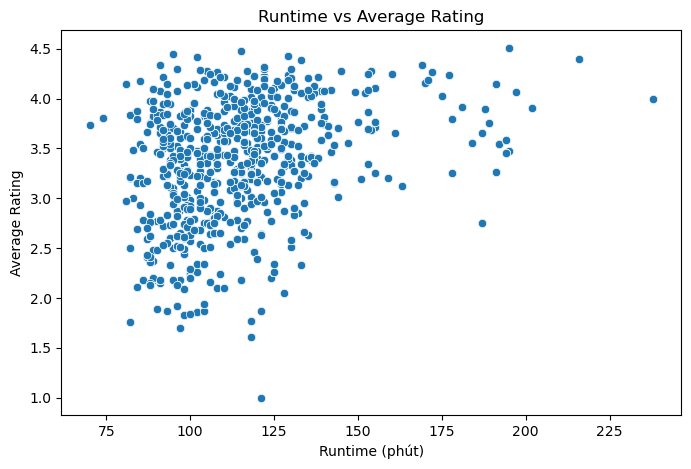

Hệ số tương quan Pearson: 0.272


In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.scatterplot(x='runtime', y='avg_rating', data=df)
plt.title("Runtime vs Average Rating")
plt.xlabel("Runtime (phút)")
plt.ylabel("Average Rating")
plt.show()

corr = df['runtime'].corr(df['avg_rating'])
print(f"Hệ số tương quan Pearson: {corr:.3f}")


# Ảnh hưởng của độ dài phim đến rating

- Hệ số tương quan Pearson giữa **runtime** và **avg_rating**: **r = 0.272**

### Nhận xét

1. Giá trị **r = 0.272** > 0 → **phim dài hơn có xu hướng được đánh giá cao hơn**, tức có mối quan hệ thuận giữa độ dài phim và rating.
2. Tuy nhiên, r < 0.3 → **mối quan hệ tương đối yếu**, nghĩa là độ dài phim chỉ giải thích một phần nhỏ sự thay đổi rating.
3. Kết hợp với scatter plot, ta có thể thấy:
   - Một số phim ngắn cũng được đánh giá cao
   - Một số phim dài lại có rating thấp
   → chứng tỏ còn nhiều yếu tố khác (thể loại, đạo diễn, diễn viên, chất lượng kịch bản...) ảnh hưởng đến rating.
4. Kết luận: **độ dài phim có ảnh hưởng tích cực đến rating nhưng mức độ không quá mạnh**, chỉ là một trong nhiều yếu tố.

---

In [57]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X = df[['runtime']]      # Feature liên tục
y = df['avg_rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)

print(f"Hệ số của runtime: {lr.coef_[0]:.3f}")


Hệ số của runtime: 0.006


# Ảnh hưởng của độ dài phim đến rating

## 1. Hệ số tương quan Pearson
- r = 0.272 → phim dài hơn có **xu hướng tăng rating**, nhưng mối quan hệ khá yếu.

## 2. Hệ số hồi quy Linear Regression
- Hệ số `runtime` = 0.006 → nghĩa là **mỗi 1 phút tăng thêm**, rating trung bình tăng khoảng **0.006 điểm** trên thang 0–5.
- Ví dụ, một phim dài hơn 100 phút so với phim khác trung bình sẽ được đánh giá cao hơn ~0.6 điểm, nếu chỉ xét riêng độ dài.

## 3. Nhận xét tổng thể
1. **Ảnh hưởng tích cực nhưng rất nhỏ**: dù hệ số dương, nhưng mức tăng rating trung bình mỗi phút phim là rất nhỏ.
2. **Mối quan hệ không mạnh**: kết hợp với r = 0.272, độ dài phim chỉ giải thích một phần nhỏ sự thay đổi rating.
3. **Yếu tố khác vẫn quan trọng hơn**: thể loại, kịch bản, diễn viên, đạo diễn... có ảnh hưởng lớn hơn nhiều.

## 4. Kết luận
- **Độ dài phim có tác động tích cực đến rating**, nhưng mức độ rất thấp.  
- Không nên đánh giá rating chỉ dựa vào runtime; đây chỉ là một trong nhiều yếu tố quyết định.


In [58]:
bins = [0, 90, 120, 180, 500]
labels = ['Ngắn', 'Vừa', 'Dài', 'Rất dài']
df['length_group'] = pd.cut(df['runtime'], bins=bins, labels=labels)
df.groupby('length_group')['avg_rating'].mean()


length_group
Ngắn       3.535520
Vừa        3.503054
Dài        3.723821
Rất dài    3.940818
Name: avg_rating, dtype: float64

# Ảnh hưởng của độ dài phim đến rating theo nhóm độ dài

Dữ liệu phân nhóm theo độ dài phim (`length_group`) và rating trung bình:

| Nhóm độ dài | Rating trung bình |
|------------|-----------------|
| Ngắn       | 3.54            |
| Vừa        | 3.50            |
| Dài        | 3.72            |
| Rất dài    | 3.94            |

---

## Nhận xét

1. **Xu hướng tăng rating theo độ dài phim**:
   - Phim **ngắn và vừa** có rating trung bình ~3.50.  
   - Phim **dài và rất dài** có rating trung bình cao hơn, lần lượt ~3.72 và 3.94.  
   - Điều này chứng tỏ **phim dài hơn có xu hướng được khán giả đánh giá cao hơn**.

2. **Mức độ khác biệt**:
   - Rating tăng từ ~3.50 (ngắn/vừa) lên ~3.94 (rất dài), tức tăng khoảng **0.44 điểm** trên thang 0–5.  
   - Mức tăng này tương đối, nhưng kết hợp với hệ số hồi quy **0.006 mỗi phút**, ta thấy **ảnh hưởng thực tế không quá mạnh trên từng phút phim**, nhưng tổng thể nhóm phim dài có rating cao hơn rõ rệt.

3. **Kết luận**:
   - Nhóm phim dài và rất dài được đánh giá cao hơn trung bình, nhưng **runtime chỉ là một trong nhiều yếu tố** quyết định rating.  
   - Nên kết hợp với các yếu tố khác như **thể loại, kịch bản, diễn viên** để phân tích toàn diện.


In [46]:
# import cudf
# import cupy as cp
# from cuml.model_selection import train_test_split

df = tmdb_exploded.copy()
# df = genre_rating.copy()

# # pandas_df là dataframe gốc
# gdf = cudf.from_pandas(df)

# # Tách GPU-native
# X_train, X_test, y_train, y_test = train_test_split(
#     gdf.drop("label", axis=1),
#     gdf["label"],
#     test_size=0.2,
#     random_state=42
# )

# --- Biến X và y  ---
X = df[['runtime']]        # Thể loại là feature
y = df['avg_rating']          # vote_average là target

#One-hot encode cho cột Genres
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(), ['runtime'])
    ],
    remainder='drop'
)

X = preprocessor.fit_transform(X)

# Danh sách model
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Random Forest": RandomForestRegressor(),
    "KNN": KNeighborsRegressor()
}

# Train - Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

import cupy as cp
import cupyx.scipy.sparse as cpx_sparse

# chuyển sang CuPy CSR
# X_train = cpx_sparse.csr_matrix((
#     cp.asarray(X_train.data),
#     cp.asarray(X_train.indices),
#     cp.asarray(X_train.indptr)
# ), shape=X_train.shape)

# X_test = cpx_sparse.csr_matrix((
#     cp.asarray(X_test.data),
#     cp.asarray(X_test.indices),
#     cp.asarray(X_test.indptr)
# ), shape=X_test.shape)
# y_train = cp.asarray(y_train)
# y_test = cp.asarray(y_test)


X_train = cp.asarray(X_train.toarray())
X_test  = cp.asarray(X_test.toarray())
y_train = cp.asarray(y_train)
# y_test  = cp.asarray(y_test)


In [47]:
from sklearn.metrics import r2_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

def evaluate_model(name, model):
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test).get()
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  rmse = np.sqrt(mse)
  print(f"{name}")
  print(f"MAE = {mae:.2f}")
  print(f"MSE = {mse:.2f}")
  print(f"RMSE = {rmse:.2f}\n")

for name, model in models.items():
  evaluate_model(name, model)

Linear Regression
MAE = 0.32
MSE = 0.19
RMSE = 0.44

Ridge Regression
MAE = 0.32
MSE = 0.19
RMSE = 0.44

Lasso Regression
MAE = 0.42
MSE = 0.27
RMSE = 0.52

Random Forest
MAE = 0.36
MSE = 0.22
RMSE = 0.47

KNN
MAE = 0.34
MSE = 0.22
RMSE = 0.47



Thời lượng phim thể hiện tác động rất yếu đến vote_average. Biểu đồ phân tán (runtime vs vote_average) cho thấy mối quan hệ gần như không tuyến tính, độ phân tán lớn, và hệ số hồi quy của runtime trong mô hình tuyến tính có giá trị nhỏ, thậm chí sát 0. Điều này chứng minh rằng độ dài phim không phải yếu tố chủ đạo quyết định việc khán giả đánh giá phim cao hay thấp.

Một lý do hợp lý là: thời lượng chỉ là yếu tố kỹ thuật và phục vụ cấu trúc nội dung; chất lượng của nội dung, mạch truyện, hoặc sức hấp dẫn của diễn xuất mới là những yếu tố định hình cảm nhận của người xem — và những yếu tố này không được phản ánh trực tiếp qua số phút runtime.

Ngoài ra, mô hình Random Forest cũng cho thấy feature importance của runtime rất thấp (thường <0.05), xác nhận kết quả từ mô hình tuyến tính.

### 3. Yếu tố Nhân sự & Thời gian
Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

## Kết luận và Trực quan hóa